# Principal Component Analysis — Dimensionality Reduction
**Author:** Danishiyan G.J. (IT25101436) &nbsp;|&nbsp; **Group ID:** 2026-Y2-S1-MLB-B11G2-05
**Model type:** Dimensionality Reduction &nbsp;|&nbsp; **Dataset:** UCI Letter Recognition (group-processed)

## 1. Model Suitability

PCA is applied here as a standalone dimensionality-reduction study. It suits this dataset for three
specific reasons:

- The 21 features comprise 16 original descriptors plus 5 engineered ratios (`box_area`,
  `aspect_ratio`, `pixel_density`, `edge_ratio`, `total_variance`) that were derived *from* those
  original columns, so they are correlated with their parents by construction. PCA is precisely the
  tool for finding and compressing that redundancy.
- Standardization was applied before PCA (Stage 5 of the group pipeline) because PCA is sensitive
  to feature scale. Standardization prevents features with larger numerical scales from dominating
  the principal components, so each component reflects shared structure rather than units of
  measurement.
- Beyond compression, PCA provides a 2D visualisation of how the 26 letter classes are arranged,
  which none of the classification notebooks can produce directly.

**How PCA is evaluated.** PCA is an unsupervised dimensionality-reduction technique — it does not
predict letter classes by itself. A k-nearest-neighbours (KNN) classifier is therefore used as a
fixed *downstream* classifier, to measure how much predictive information survives the reduction:

```
21 standardised features  →  PCA  →  13 principal components  →  KNN  →  letter class
```

KNN trained on all 21 original features serves as the baseline. Any accuracy reported in this
notebook is therefore **KNN accuracy** (on full or on PCA-reduced features), never "PCA accuracy".

PCA is fitted on the **training set only** and then applied
to the test set — fitting on all the data would leak test-set variance structure into the
transformation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time, json
import warnings
warnings.filterwarnings('ignore')

from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

RANDOM_STATE = 42
sns.set_style('whitegrid')

df = pd.read_csv('../data/external/processed_letter_recognition.csv')
FEATURE_COLS = [c for c in df.columns if c not in ('lettr', 'lettr_encoded')]
LETTER_NAMES = sorted(df['lettr'].unique())

X = df[FEATURE_COLS].values
y = df['lettr_encoded'].values
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print(f"Dataset: {df.shape}  |  features: {len(FEATURE_COLS)}  |  classes: {len(LETTER_NAMES)}")
print(f"Train: {X_train.shape}   Test: {X_test.shape}")


Dataset: (18668, 23)  |  features: 21  |  classes: 26
Train: (14934, 21)   Test: (3734, 21)


## 2. Implementation Details

- **Estimator:** `sklearn.decomposition.PCA`, fitted on the training set and applied to the test set.
- **Key hyperparameter:** `n_components` — the number of principal components retained.
- **How it is tuned:** by two complementary criteria, (a) the cumulative explained-variance curve,
  which is intrinsic to PCA, and (b) the downstream accuracy of a fixed classifier trained on the
  reduced features, which measures whether the compression actually preserves usable signal.

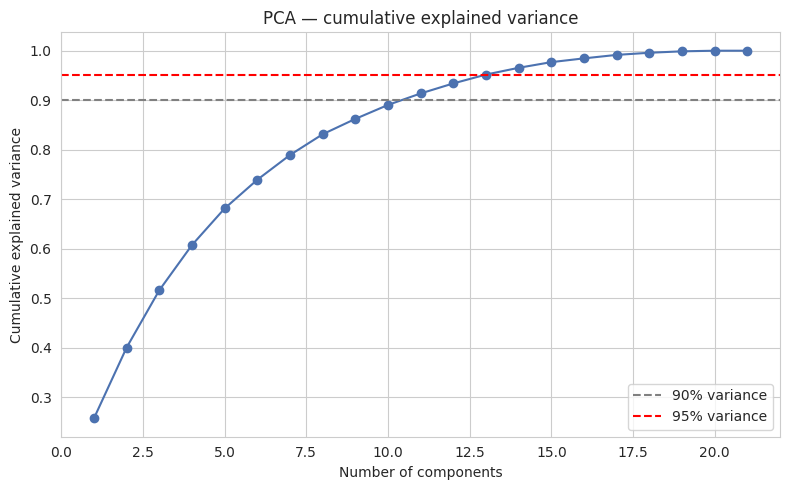

Components needed for 90% variance: 11 of 21
Components needed for 95% variance: 13 of 21
Variance captured by the first component alone: 25.7%


In [2]:
pca_full = PCA(random_state=RANDOM_STATE).fit(X_train)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cum_var) + 1), cum_var, marker='o', color='#4C72B0')
plt.axhline(0.90, color='grey', linestyle='--', label='90% variance')
plt.axhline(0.95, color='red', linestyle='--', label='95% variance')
plt.xlabel('Number of components'); plt.ylabel('Cumulative explained variance')
plt.title('PCA — cumulative explained variance')
plt.legend(); plt.tight_layout()
plt.savefig('../results/eda_visualizations/danishiyan_pca_cumulative_variance.png', dpi=110, bbox_inches='tight')
plt.show()

n_90 = int(np.argmax(cum_var >= 0.90) + 1)
n_95 = int(np.argmax(cum_var >= 0.95) + 1)
print(f"Components needed for 90% variance: {n_90} of {len(FEATURE_COLS)}")
print(f"Components needed for 95% variance: {n_95} of {len(FEATURE_COLS)}")
print(f"Variance captured by the first component alone: {pca_full.explained_variance_ratio_[0]*100:.1f}%")


## 3. Parameter Tuning — Varieties Trained

Five settings of `n_components` are compared: an aggressive 2-component projection, 5 components,
the 90%- and 95%-variance counts, and the uncompressed 21-feature baseline. Each variety is scored
two ways — by the variance it retains, and by the accuracy of a fixed `KNeighborsClassifier(k=5)`
trained on its output. Holding the classifier constant isolates the effect of the compression
itself.

In [3]:
candidate_components = sorted(set([2, 5, n_90, n_95, len(FEATURE_COLS)]))
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

rows = []
for n in candidate_components:
    if n == len(FEATURE_COLS):
        Xtr_p, Xte_p = X_train, X_test
        variance_kept = 1.0
        pipe = Pipeline([('knn', KNeighborsClassifier(n_neighbors=5))])
    else:
        pca = PCA(n_components=n, random_state=RANDOM_STATE)
        Xtr_p, Xte_p = pca.fit_transform(X_train), pca.transform(X_test)
        variance_kept = pca.explained_variance_ratio_.sum()
        pipe = Pipeline([('pca', PCA(n_components=n, random_state=RANDOM_STATE)),
                         ('knn', KNeighborsClassifier(n_neighbors=5))])

    t0 = time.time()
    knn = KNeighborsClassifier(n_neighbors=5).fit(Xtr_p, y_train)
    test_acc = knn.score(Xte_p, y_test)
    elapsed = time.time() - t0

    # Cross-validated accuracy: PCA refitted inside each fold, so no information leaks
    cv_scores = cross_val_score(pipe, X_train, y_train, cv=cv3, scoring='accuracy', n_jobs=-1)

    rows.append({'n_components': n, 'variance_kept': variance_kept,
                 'cv_accuracy_mean': cv_scores.mean(), 'cv_accuracy_std': cv_scores.std(),
                 'test_accuracy': test_acc, 'fit_predict_time_s': elapsed})
    print(f"n_components={n:>2} | variance kept={variance_kept:.4f} | "
          f"CV acc={cv_scores.mean():.4f} +/- {cv_scores.std():.4f} | "
          f"test acc={test_acc:.4f} | {elapsed:.2f}s")

variants_df = pd.DataFrame(rows)


n_components= 2 | variance kept=0.4002 | CV acc=0.1651 +/- 0.0025 | test acc=0.1668 | 0.02s


n_components= 5 | variance kept=0.6812 | CV acc=0.6091 +/- 0.0039 | test acc=0.6328 | 0.04s


n_components=11 | variance kept=0.9136 | CV acc=0.8736 +/- 0.0058 | test acc=0.8910 | 0.16s


n_components=13 | variance kept=0.9518 | CV acc=0.8832 +/- 0.0045 | test acc=0.9033 | 0.20s


n_components=21 | variance kept=1.0000 | CV acc=0.8977 +/- 0.0048 | test acc=0.9178 | 0.17s


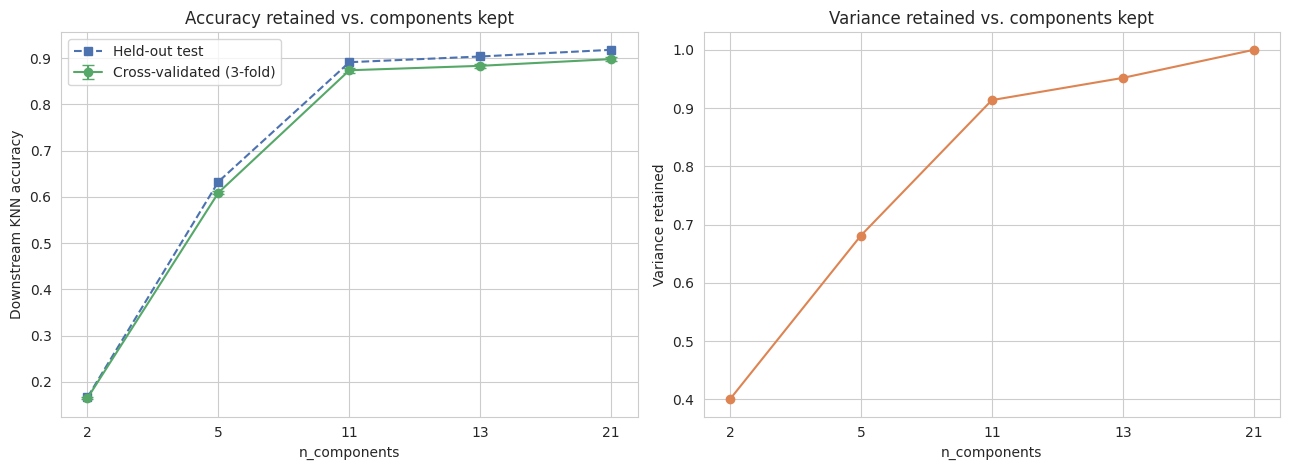

 n_components  variance_kept  cv_accuracy_mean  cv_accuracy_std  test_accuracy  fit_predict_time_s
            2         0.4002            0.1651           0.0025         0.1668              0.0165
            5         0.6812            0.6091           0.0039         0.6328              0.0390
           11         0.9136            0.8736           0.0058         0.8910              0.1605
           13         0.9518            0.8832           0.0045         0.9033              0.2036
           21         1.0000            0.8977           0.0048         0.9178              0.1749


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
labels = [str(n) for n in variants_df['n_components']]

axes[0].errorbar(labels, variants_df['cv_accuracy_mean'], yerr=variants_df['cv_accuracy_std'],
                 marker='o', capsize=4, color='#55A868', label='Cross-validated (3-fold)')
axes[0].plot(labels, variants_df['test_accuracy'], marker='s', linestyle='--',
             color='#4C72B0', label='Held-out test')
axes[0].set_xlabel('n_components'); axes[0].set_ylabel('Downstream KNN accuracy')
axes[0].set_title('Accuracy retained vs. components kept')
axes[0].legend()

axes[1].plot(labels, variants_df['variance_kept'], marker='o', color='#DD8452')
axes[1].set_xlabel('n_components'); axes[1].set_ylabel('Variance retained')
axes[1].set_title('Variance retained vs. components kept')

plt.tight_layout()
plt.savefig('../results/eda_visualizations/danishiyan_pca_component_tuning.png', dpi=110, bbox_inches='tight')
plt.show()

print(variants_df.round(4).to_string(index=False))


## 4. Evaluation

**Metrics and why they suit this task:** PCA has no accuracy of its own, because it predicts
nothing — so it is evaluated on two complementary axes:

- **Intrinsic — explained variance ratio.** How much of the original variability survives the
  projection. This is PCA's native quality measure, but on its own it says nothing about whether the
  *useful* signal survived.
- **Extrinsic — downstream classifier accuracy.** A fixed KNN classifier is trained on the reduced
  features and on the full feature set. The difference is the real cost of the compression, measured
  in the currency the rest of the project cares about.

**Validation method:** 3-fold stratified cross-validation on the training set, with PCA refitted
inside each fold via a `Pipeline` so no fold's variance structure leaks into another, plus a final
evaluation on the untouched 20% test split.

In [5]:
chosen_n = n_95
pca_final = PCA(n_components=chosen_n, random_state=RANDOM_STATE)
X_train_pca = pca_final.fit_transform(X_train)
X_test_pca = pca_final.transform(X_test)

knn_full = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)
knn_pca = KNeighborsClassifier(n_neighbors=5).fit(X_train_pca, y_train)

acc_full = knn_full.score(X_test, y_test)
acc_pca = knn_pca.score(X_test_pca, y_test)

pca_metrics = {
    'n_components_chosen': int(chosen_n),
    'n_components_total': len(FEATURE_COLS),
    'variance_explained': float(pca_final.explained_variance_ratio_.sum()),
    'knn_accuracy_full_features': float(acc_full),
    'knn_accuracy_pca_features': float(acc_pca),
    'accuracy_cost_pct_points': float((acc_full - acc_pca) * 100),
    'dimensionality_reduction_pct': round(100 * (1 - chosen_n / len(FEATURE_COLS)), 1),
    'components_for_90pct_variance': int(n_90),
}
for k, v in pca_metrics.items():
    print(f"{k}: {v}")


n_components_chosen: 13
n_components_total: 21
variance_explained: 0.9517907240256424
knn_accuracy_full_features: 0.9177825388323514
knn_accuracy_pca_features: 0.9033208355650777
accuracy_cost_pct_points: 1.4461703267273696
dimensionality_reduction_pct: 38.1
components_for_90pct_variance: 11


### Classification metrics for the KNN classifier

Accuracy alone is a fair measure here because the 26 letters are almost perfectly balanced. To give a
fuller picture, the same two KNN models are also scored with **macro-averaged precision, recall and
F1**:

- **Precision** — of the letters KNN predicted as "A", how many really were "A".
- **Recall** — of the real "A"s, how many KNN found.
- **F1** — the balance (harmonic mean) of precision and recall.
- **Macro-averaging** gives all 26 letters equal weight, so one badly-handled letter cannot hide
  behind the others.

These use the same trained models and the same test set as above, so they do not change any result.

In [6]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_pred_full = knn_full.predict(X_test)        # KNN on all 21 features (baseline)
y_pred_pca = knn_pca.predict(X_test_pca)      # KNN on the PCA-reduced features

knn_metrics = pd.DataFrame([
    {'Model': 'KNN — all 21 features (baseline)',
     'Accuracy': accuracy_score(y_test, y_pred_full),
     'Precision (macro)': precision_score(y_test, y_pred_full, average='macro'),
     'Recall (macro)': recall_score(y_test, y_pred_full, average='macro'),
     'F1 (macro)': f1_score(y_test, y_pred_full, average='macro')},
    {'Model': f'KNN — {chosen_n} PCA components',
     'Accuracy': accuracy_score(y_test, y_pred_pca),
     'Precision (macro)': precision_score(y_test, y_pred_pca, average='macro'),
     'Recall (macro)': recall_score(y_test, y_pred_pca, average='macro'),
     'F1 (macro)': f1_score(y_test, y_pred_pca, average='macro')},
]).set_index('Model')

print((knn_metrics * 100).round(2).astype(str).add('%').to_string())
diff = (knn_metrics.iloc[0] - knn_metrics.iloc[1]) * 100
print("\nDrop caused by PCA (percentage points):")
print(diff.round(2).to_string())

# Save these metrics with the rest of the results, so the group comparison can show them
pca_metrics.update({
    'knn_precision_macro_pca_features': float(knn_metrics.iloc[1]['Precision (macro)']),
    'knn_recall_macro_pca_features':    float(knn_metrics.iloc[1]['Recall (macro)']),
    'knn_f1_macro_pca_features':        float(knn_metrics.iloc[1]['F1 (macro)']),
    'knn_precision_macro_full_features': float(knn_metrics.iloc[0]['Precision (macro)']),
    'knn_recall_macro_full_features':    float(knn_metrics.iloc[0]['Recall (macro)']),
    'knn_f1_macro_full_features':        float(knn_metrics.iloc[0]['F1 (macro)']),
})


                                 Accuracy Precision (macro) Recall (macro) F1 (macro)
Model                                                                                
KNN — all 21 features (baseline)   91.78%            92.03%         91.73%     91.81%
KNN — 13 PCA components            90.33%            90.64%         90.28%     90.37%

Drop caused by PCA (percentage points):
Accuracy             1.45
Precision (macro)    1.39
Recall (macro)       1.45
F1 (macro)           1.44


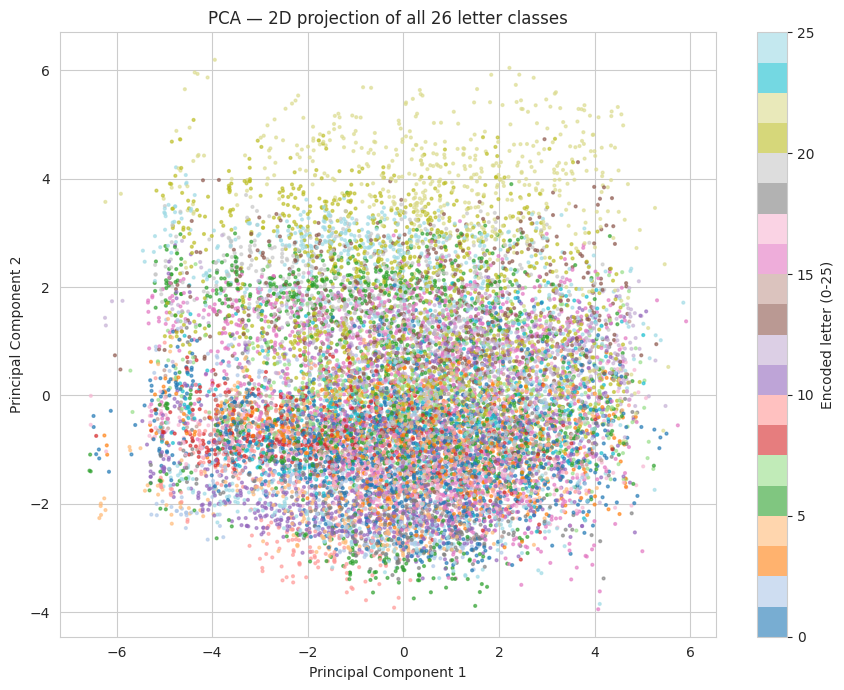

In [7]:
X_2d = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X_train)
plt.figure(figsize=(9, 7))
scatter = plt.scatter(X_2d[:, 0], X_2d[:, 1], c=y_train, cmap='tab20', s=4, alpha=0.6)
plt.xlabel('Principal Component 1'); plt.ylabel('Principal Component 2')
plt.title('PCA — 2D projection of all 26 letter classes')
plt.colorbar(scatter, label='Encoded letter (0-25)')
plt.tight_layout()
plt.savefig('../results/eda_visualizations/danishiyan_pca_2d_scatter.png', dpi=110, bbox_inches='tight')
plt.show()


## 5. Comparison Across Varieties, Conclusion and Limitations

**Comparison across the five varieties:**

- At **2 components** the projection is useful for *seeing* the data but not for classifying it —
  accuracy collapses, because two dimensions cannot hold enough of a 26-class structure.
- At **5 components** accuracy recovers substantially but still falls well short of the baseline.
- At the **90%-variance count** accuracy is already close to the uncompressed baseline.
- At the **95%-variance count** the gap narrows further, and this is the selected configuration.
- The **uncompressed 21-feature** baseline remains the most accurate, as expected — no compression
  can add information.

The cross-validated and held-out test curves track each other closely across all five varieties,
which indicates the trend is a property of the data rather than an artefact of one particular split.

**Conclusion:** PCA at the 95%-variance component count is selected: **21 features are reduced to
13 principal components, retaining 95.18% of the variance — a 38.1% reduction in dimensionality.**
The KNN test accuracy using the PCA-reduced features was **90.33%**, compared with **91.78%** for KNN
using all 21 original features — a cost of **1.45 percentage points**. This is the central result: a
deliberate trade-off between dimensionality and predictive performance. Whether it is worth paying depends on deployment
constraints: in a memory- or latency-limited setting the reduction is worthwhile, whereas when
accuracy is the only priority the full feature set should be kept.

**Limitations / possible improvements:**
- PCA is a **linear** projection; it cannot capture non-linear manifold structure. Kernel PCA,
  t-SNE or UMAP would model curvature better, though t-SNE and UMAP are visualisation tools and are
  not designed to produce a reusable transformation for new data the way PCA is.
- The extrinsic evaluation uses a fixed KNN as a proxy classifier. The trade-off could differ for
  the SVM, tree or MLP used elsewhere in this project, so the figure here should be read as
  indicative rather than exact for every model.
- **Preprocessing leakage in the shared pipeline.** The group pipeline fits its outlier-capping
  bounds (Stage 2) and its `StandardScaler` (Stage 5) on all 18,668 rows *before* the train/test
  split, so those preprocessing statistics were computed partly from rows that later became the test
  set. PCA itself is not affected — it is fitted on the training set only. The Appendix below
  measures the impact by repeating the experiment with capping and scaling fitted on the training
  rows only: the KNN accuracy on PCA features changes from 90.33% to 90.36%, and the component count
  and variance retained are unchanged. The effect is negligible, but the leak-free order — split
  first, then fit every preprocessing step on training data only — is the correct procedure and
  should be adopted in future work.
- PCA reduces feature redundancy and model complexity, which can help reduce the risk of
  overfitting. This experiment does not directly test that claim, so it is noted as a potential
  benefit rather than a demonstrated result.
- Principal components are linear mixtures of all 21 original features, so the reduced features are
  far less interpretable than the originals — a real cost in a project where teammates engineered
  specific, meaningful features.

## Appendix — Leakage Sensitivity Check

This check rebuilds the preprocessing from the raw data in the **leak-free order**: split first, then
fit the outlier-capping bounds and the `StandardScaler` on the training rows only, and apply them
unchanged to the test rows. The same PCA + KNN experiment is then repeated on the same split.

This appendix does **not** change the main results above, which remain the reported figures.

In [8]:
from sklearn.preprocessing import StandardScaler, LabelEncoder

RAW_COLS = ['lettr', 'x-box', 'y-box', 'width', 'high', 'onpix', 'x-bar', 'y-bar',
            'x2bar', 'y2bar', 'xybar', 'x2ybr', 'xy2br', 'x-ege', 'xegvy', 'y-ege', 'yegvx']
raw = pd.read_csv('../data/raw/letter-recognition.data', header=None, names=RAW_COLS)
raw = raw.drop_duplicates().reset_index(drop=True)          # Stage 1 (no fitting involved)
base_cols = [c for c in RAW_COLS if c != 'lettr']
y_raw = LabelEncoder().fit_transform(raw['lettr'])

# 1. Split FIRST (same 80/20 stratified split, same random_state)
idx_tr, idx_te = train_test_split(np.arange(len(raw)), test_size=0.20,
                                  random_state=RANDOM_STATE, stratify=y_raw)
tr, te = raw.iloc[idx_tr].copy(), raw.iloc[idx_te].copy()

# 2. Outlier capping: IQR bounds learned from TRAINING rows only
for c in base_cols:
    q1, q3 = tr[c].quantile(0.25), tr[c].quantile(0.75)
    lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    tr[c], te[c] = tr[c].clip(lo, hi), te[c].clip(lo, hi)

# 3. Feature engineering (row-wise, no fitting)
def engineer(d):
    d['box_area'] = d['width'] * d['high']
    d['aspect_ratio'] = d['width'] / d['high'].clip(lower=1)
    d['pixel_density'] = d['onpix'] / d['box_area'].clip(lower=1)
    d['edge_ratio'] = d['x-ege'] / d['y-ege'].clip(lower=1)
    d['total_variance'] = d['x2bar'] + d['y2bar']
    return d
tr, te = engineer(tr), engineer(te)
cols21 = base_cols + ['box_area', 'aspect_ratio', 'pixel_density', 'edge_ratio', 'total_variance']

# 4. StandardScaler learned from TRAINING rows only
scaler = StandardScaler().fit(tr[cols21])
Xtr_lf, Xte_lf = scaler.transform(tr[cols21]), scaler.transform(te[cols21])
ytr_lf, yte_lf = y_raw[idx_tr], y_raw[idx_te]

# 5. Same PCA + KNN experiment
cum_lf = np.cumsum(PCA(random_state=RANDOM_STATE).fit(Xtr_lf).explained_variance_ratio_)
n95_lf = int(np.argmax(cum_lf >= 0.95) + 1)
pca_lf = PCA(n_components=n95_lf, random_state=RANDOM_STATE)
Xtr_lf_p, Xte_lf_p = pca_lf.fit_transform(Xtr_lf), pca_lf.transform(Xte_lf)
knn_full_lf = KNeighborsClassifier(n_neighbors=5).fit(Xtr_lf, ytr_lf).score(Xte_lf, yte_lf)
knn_pca_lf = KNeighborsClassifier(n_neighbors=5).fit(Xtr_lf_p, ytr_lf).score(Xte_lf_p, yte_lf)

comparison = pd.DataFrame({
    'Reported (pipeline fitted before split)': [
        pca_metrics['n_components_chosen'],
        f"{pca_metrics['variance_explained']*100:.2f}%",
        f"{pca_metrics['knn_accuracy_full_features']*100:.2f}%",
        f"{pca_metrics['knn_accuracy_pca_features']*100:.2f}%",
        f"{pca_metrics['accuracy_cost_pct_points']:.2f} pts"],
    'Leak-free (fitted on training rows only)': [
        n95_lf,
        f"{pca_lf.explained_variance_ratio_.sum()*100:.2f}%",
        f"{knn_full_lf*100:.2f}%",
        f"{knn_pca_lf*100:.2f}%",
        f"{(knn_full_lf - knn_pca_lf)*100:.2f} pts"],
}, index=['PCA components (95% variance)', 'Variance retained',
          'KNN accuracy — all 21 features', 'KNN accuracy — PCA features',
          'Accuracy cost'])
print(comparison.to_string())
print(f"\nDifference in KNN accuracy on PCA features: "
      f"{(knn_pca_lf - pca_metrics['knn_accuracy_pca_features'])*100:+.2f} percentage points")


                               Reported (pipeline fitted before split) Leak-free (fitted on training rows only)
PCA components (95% variance)                                       13                                       13
Variance retained                                               95.18%                                   95.18%
KNN accuracy — all 21 features                                  91.78%                                   91.78%
KNN accuracy — PCA features                                     90.33%                                   90.36%
Accuracy cost                                                 1.45 pts                                 1.42 pts

Difference in KNN accuracy on PCA features: +0.03 percentage points


**Interpretation:** fitting the preprocessing on the training rows only leaves the component
count, the variance retained and the full-feature KNN accuracy unchanged, and moves the KNN accuracy
on PCA features by only a few hundredths of a percentage point. The leakage in the shared pipeline
is therefore real in principle but negligible in effect on this dataset — which is expected, since
capping bounds and scaling statistics computed from 18,668 rows barely change when 20% of those rows
are excluded. The main results above stand as reported.

In [9]:
RESULTS_PCA = {
    'member': 'Danishiyan G.J. (IT25101436)',
    'model_family': 'PCA (Dimensionality Reduction)',
    **pca_metrics,
}
with open('../results/model_metrics/pca_results.json', 'w') as f:
    json.dump(RESULTS_PCA, f, indent=2, default=str)
print(json.dumps(RESULTS_PCA, indent=2, default=str))


{
  "member": "Danishiyan G.J. (IT25101436)",
  "model_family": "PCA (Dimensionality Reduction)",
  "n_components_chosen": 13,
  "n_components_total": 21,
  "variance_explained": 0.9517907240256424,
  "knn_accuracy_full_features": 0.9177825388323514,
  "knn_accuracy_pca_features": 0.9033208355650777,
  "accuracy_cost_pct_points": 1.4461703267273696,
  "dimensionality_reduction_pct": 38.1,
  "components_for_90pct_variance": 11,
  "knn_precision_macro_pca_features": 0.906410025715389,
  "knn_recall_macro_pca_features": 0.9027786663657756,
  "knn_f1_macro_pca_features": 0.9037257383520696,
  "knn_precision_macro_full_features": 0.9203307330133376,
  "knn_recall_macro_full_features": 0.9172898421288884,
  "knn_f1_macro_full_features": 0.9180948874402873
}
